<a href="https://colab.research.google.com/github/ajasrotiabe/imgprocessing/blob/main/assignment10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving _ (12).jpeg to _ (12).jpeg
Enter initial window size (odd number): 5
Enter maximum window size (odd number): 7


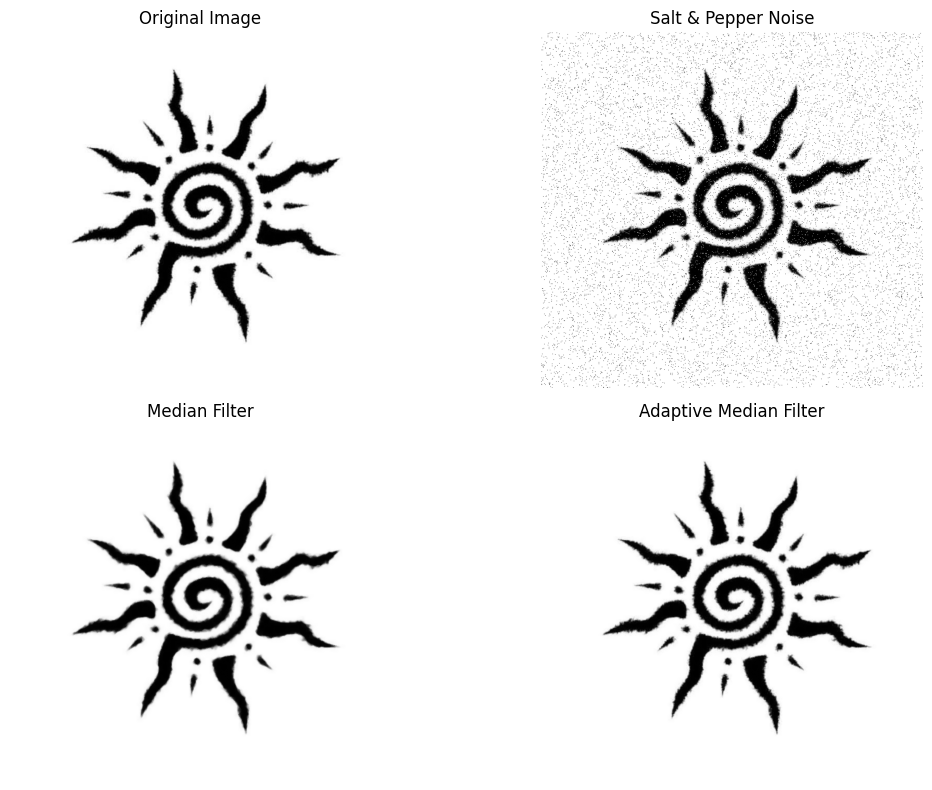

PSNR Comparison
----------------------
Noisy Image: 16.17174546724686 dB
Median Filter: 34.656207916367656 dB
Adaptive Median Filter: 44.252665150644575 dB


In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
from google.colab import files
uploaded = files.upload()

img = cv2.imread(list(uploaded.keys())[0], cv2.IMREAD_GRAYSCALE)

# Add salt and pepper noise
def add_salt_pepper(image, amount=0.05):
    noisy = image.copy()
    total = image.size
    num = int(total * amount / 2)

    coords = [np.random.randint(0, i, num) for i in image.shape]
    noisy[coords[0], coords[1]] = 255

    coords = [np.random.randint(0, i, num) for i in image.shape]
    noisy[coords[0], coords[1]] = 0

    return noisy

noisy = add_salt_pepper(img)

# Input window sizes
Smin = int(input("Enter initial window size (odd number): "))
Smax = int(input("Enter maximum window size (odd number): "))

if Smin < 3 or Smin % 2 == 0 or Smax % 2 == 0 or Smax < Smin:
    raise ValueError("Enter valid odd window sizes, with Smin >= 3 and Smax >= Smin.")

# Normal median filter
median_result = cv2.medianBlur(noisy, Smin)

# Adaptive Median Filter
def adaptive_median(image, Smin, Smax):
    h, w = image.shape
    result = np.zeros_like(image)

    max_radius = Smax // 2
    padded = cv2.copyMakeBorder(
        image, max_radius, max_radius,
        max_radius, max_radius,
        cv2.BORDER_REFLECT
    )

    for i in range(h):
        for j in range(w):
            window_size = Smin
            output = None

            while window_size <= Smax:
                r = window_size // 2

                window = padded[
                    i + max_radius - r : i + max_radius + r + 1,
                    j + max_radius - r : j + max_radius + r + 1
                ]

                zmin = np.min(window)
                zmax = np.max(window)
                zmed = np.median(window)
                zxy = padded[i + max_radius, j + max_radius]

                # Stage A
                if zmin < zmed < zmax:

                    # Stage B
                    if zmin < zxy < zmax:
                        output = zxy
                    else:
                        output = zmed

                    break

                else:
                    window_size += 2

            if output is None:
                output = zmed

            result[i, j] = output

    return result.astype(np.uint8)

adaptive_result = adaptive_median(noisy, Smin, Smax)

# PSNR calculation
def calculate_psnr(original, filtered):
    mse = np.mean((original.astype(float) - filtered.astype(float)) ** 2)

    if mse == 0:
        return float('inf')

    return 10 * np.log10((255 ** 2) / mse)

psnr_noisy = calculate_psnr(img, noisy)
psnr_median = calculate_psnr(img, median_result)
psnr_adaptive = calculate_psnr(img, adaptive_result)

# Display images
images = [img, noisy, median_result, adaptive_result]
titles = ["Original Image", "Salt & Pepper Noise",
          "Median Filter", "Adaptive Median Filter"]

plt.figure(figsize=(12, 8))

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

# Display PSNR values
print("PSNR Comparison")
print("----------------------")
print("Noisy Image:", psnr_noisy, "dB")
print("Median Filter:", psnr_median, "dB")
print("Adaptive Median Filter:", psnr_adaptive, "dB")


Saving _ (12).jpeg to _ (12) (1).jpeg
Optimal Otsu Threshold: 136.0


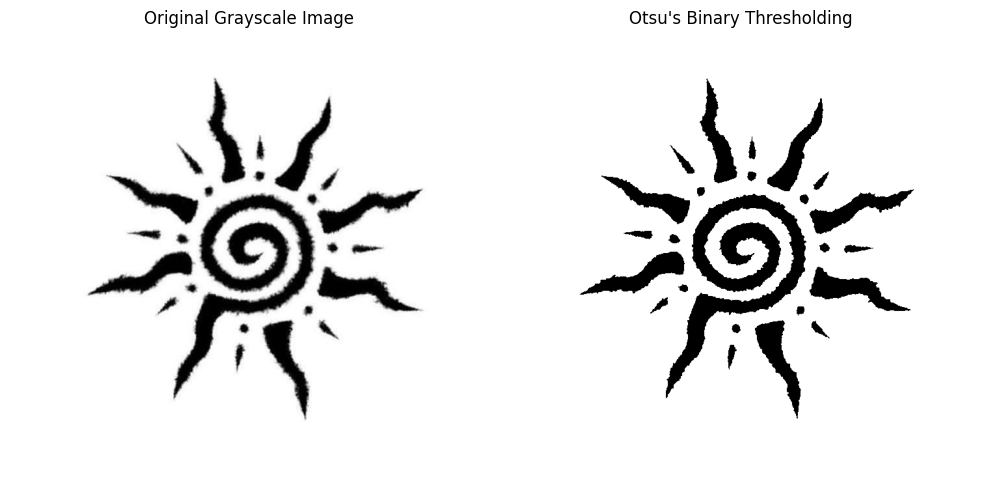

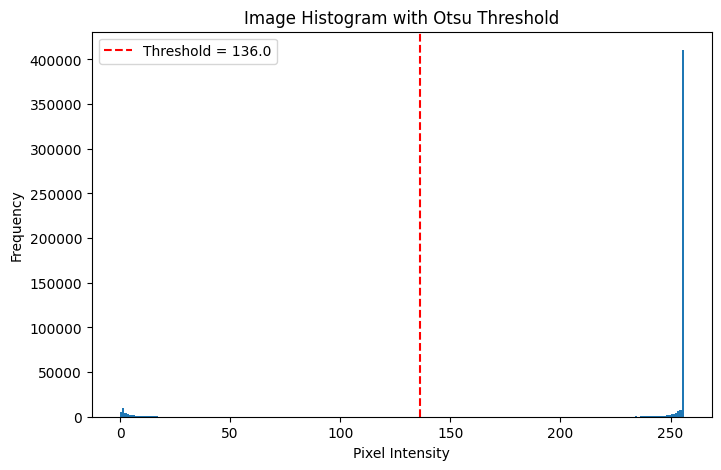

In [2]:

import cv2
import matplotlib.pyplot as plt
from google.colab import files

# Upload image
uploaded = files.upload()

# Read grayscale image
img = cv2.imread(list(uploaded.keys())[0], cv2.IMREAD_GRAYSCALE)

# Apply Otsu's thresholding
threshold, binary = cv2.threshold(
    img,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Display threshold value
print("Optimal Otsu Threshold:", threshold)

# Display original and segmented images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap='gray')
plt.title("Otsu's Binary Thresholding")
plt.axis('off')

plt.tight_layout()
plt.show()

# Display histogram and threshold
plt.figure(figsize=(8, 5))
plt.hist(img.ravel(), bins=256, range=(0, 256))
plt.axvline(threshold, color='red', linestyle='--',
            label=f'Threshold = {threshold}')

plt.title("Image Histogram with Otsu Threshold")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()
plt.show()
